# 05. TabPFN을 GBDT로 옮기기 — 증류

TabPFN은 예측할 때마다 학습 행 전체를 context로 넣고 7M 파라미터 Transformer를 멤버 수만큼 돌립니다. 정확하지만 무겁고, 실제 서비스에서는 GPU가 있어야 빠릅니다. 증류(distillation)는 TabPFN(teacher)이 낸 예측 확률을 GBDT(학생)에게 배우게 해서, 예측은 학생만으로 합니다. 학생은 나무 몇백 그루라 CPU에서 행 하나에 1ms도 걸리지 않습니다. 이 저장소의 구현은 `minipfn/inference/distillation.py`의 `DistilledClassifier`·`DistilledRegressor`입니다(issue #44).

이 노트북의 학생은 sklearn의 HistGradientBoosting(`student="hist"`)입니다. XGBoost·LightGBM 학생도 같은 방식으로 쓰지만(`student="xgboost"`, `"lightgbm"`), macOS에서는 OpenMP(`brew install libomp`)가 따로 필요합니다.

다루는 흐름:

1. 학생은 무엇을 배우나 — 확률을 행 가중치로
2. 학습 행을 그대로 물으면 정답 쪽으로 기운다
3. 두 가지 처방 — out-of-fold와 CutMix 행
4. two moons에서 — 결정 경계와 예측 시간
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_inference/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. Hub에서 v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받습니다. CPU에서 1분쯤 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold

from minipfn import TabPFNv2Classifier, set_seed
from minipfn.inference import distillation
from minipfn.inference.distillation import DistilledClassifier, cutmix

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 학생은 무엇을 배우나 — 확률을 행 가중치로

정답 라벨만 배우는 보통의 GBDT는 행 하나에서 "이 행은 클래스 1"만 봅니다. teacher의 예측은 "클래스 1일 확률 0.3"처럼 더 많은 것을 알려 줍니다. 경계 근처라 헷갈린다는 정보입니다. 이 확률을 그대로 배우는 손실이 soft cross-entropy $-\sum_k p_k \log q_k$입니다($p$는 teacher, $q$는 학생의 확률).

GBDT 라이브러리는 대개 정수 라벨만 받습니다. 그래서 행을 클래스 수만큼 복제해, 클래스 $k$로 적은 복제에 가중치 $p_k$를 줍니다. 가중치가 있는 보통의 log loss가 soft cross-entropy와 같아집니다. 행 하나로 확인합니다.

In [3]:
teacher_p = np.array([0.7, 0.3])  # teacher: 클래스 0일 확률 0.7, 클래스 1일 확률 0.3
student_q = np.array([0.6, 0.4])  # 학생이 지금 내는 확률

soft_ce = -(teacher_p * np.log(student_q)).sum()

copies = pd.DataFrame({"라벨": [0, 1], "가중치": teacher_p})  # 행 하나 → 복제 2개
copies["학생의 -log q(라벨)"] = -np.log(student_q[copies["라벨"]])
weighted = (copies["가중치"] * copies["학생의 -log q(라벨)"]).sum()
display(copies.round(3))
print(f"soft cross-entropy: {soft_ce:.4f}")
print(f"복제 행의 가중 log loss: {weighted:.4f}")

,라벨,가중치,학생의 -log q(라벨)
0,0,0.7,0.511
1,1,0.3,0.916


soft cross-entropy: 0.6325
복제 행의 가중 log loss: 0.6325


두 값이 같습니다. 학생 입장에서는 행이 두 배로 늘고 가중치가 붙었을 뿐인 보통의 분류 문제입니다. 저장소는 이진 분류의 XGBoost·LightGBM 학생에는 0~1 사이 label을 그대로 받는 목적함수를 쓰고, 그 밖에는 이렇게 복제합니다.

## 2. 학습 행을 그대로 물으면 정답 쪽으로 기운다

학생에게 줄 확률은 학습 행마다 하나씩 필요합니다. 그런데 TabPFN은 학습 행을 context로 넣으므로, 학습 행을 그대로 물으면 그 행의 정답을 보고 답합니다([02](02_greedy_ensemble_selection.ipynb) 3절). 그러면 확률이 정답 라벨 쪽으로 기울어서, 학생이 teacher에게서 배울 "헷갈리는 정도"가 줄어듭니다.

two moons(초승달 두 개가 맞물린 2차원 데이터, noise 0.3)에서 학습 행 60개로 확인합니다. 같은 행을 두 가지로 물어 정답 클래스의 확률을 봅니다. 하나는 학습 행 전체를 context로 둔 것이고, 다른 하나는 5-fold out-of-fold(그 행이 빠진 context)입니다.

In [4]:
x_all, y_all = make_moons(2000, noise=0.3, random_state=0)
x_tr, y_tr = x_all[:60], y_all[:60]  # 학습 행 60개
x_te, y_te = x_all[1000:], y_all[1000:]  # test 행 1,000개

model = TabPFNv2Classifier().model  # aiden-jeon/minipfn-tabpfn-v2-classifier
teacher = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr, y_tr)
full_context = teacher.predict_proba(x_tr)  # 자기 자신이 context에 있다

out_of_fold = np.zeros_like(full_context)
folds = StratifiedKFold(distillation.N_FOLDS, shuffle=True, random_state=0)
for fit_rows, held_out_rows in folds.split(x_tr, y_tr):
    fold_teacher = TabPFNv2Classifier(model, n_estimators=4).fit(x_tr[fit_rows], y_tr[fit_rows])
    out_of_fold[held_out_rows] = fold_teacher.predict_proba(x_tr[held_out_rows])

rows = np.arange(len(y_tr))
leak = pd.DataFrame(
    {
        "x1": x_tr[:, 0],
        "x2": x_tr[:, 1],
        "정답": y_tr,
        "정답 확률 (전체 context)": full_context[rows, y_tr],
        "정답 확률 (out-of-fold)": out_of_fold[rows, y_tr],
    }
)
hardest = leak.sort_values("정답 확률 (out-of-fold)").head(5)  # out-of-fold로 가장 헷갈린 행
display(hardest.round(3))
print(
    "평균 정답 확률: 전체 context",
    round(float(leak["정답 확률 (전체 context)"].mean()), 3),
    "/ out-of-fold",
    round(float(leak["정답 확률 (out-of-fold)"].mean()), 3),
)

,x1,x2,정답,정답 확률 (전체 context),정답 확률 (out-of-fold)
52,0.962,-0.223,0,0.278,0.129
34,0.774,0.850,1,0.271,0.137
58,0.283,0.631,1,0.287,0.256
12,0.399,0.276,0,0.448,0.298
5,-0.252,0.349,1,0.418,0.299


평균 정답 확률: 전체 context 0.77 / out-of-fold 0.723


60행 평균으로 보면 정답 확률이 out-of-fold의 0.723에서 전체 context의 0.770으로 오릅니다. out-of-fold로 가장 헷갈린 다섯 행은 차이가 더 커서, 52번 행은 0.129가 0.278로 두 배가 됩니다. 이 데이터는 noise가 커서 teacher가 학습 행을 외우지는 않지만, 헷갈리는 행일수록 자기 정답 쪽으로 기웁니다. 쉬운 데이터에서는 더 심합니다. 02의 wine에서는 학습 행을 그대로 물었을 때 log loss가 0.002로, 거의 정답만 냈습니다.

## 3. 두 가지 처방 — out-of-fold와 CutMix 행

논문 두 편이 이 문제를 다르게 풉니다. `METHODS`에 묶음으로 들어 있습니다.

- **`oof`**(*Pocket Foundation Models*, arXiv 2605.18654): 2절처럼 학습 행의 확률을 5-fold out-of-fold로 냅니다. 확률이 샐 때보다 덜 확신하므로, 손실은 teacher 확률(α = 0.7)과 정답 라벨(0.3)을 섞습니다.
- **`synthetic`**(*Distillation of Tabular Foundation Models into Efficient Predictors*, arXiv 2610.01435): 학습 행은 새는 확률 그대로 쓰되, 학습 행에 없는 행을 학습 행의 2배만큼 새로 만들어 teacher에게 묻습니다. context에 없는 행이라 teacher가 정답을 볼 수 없습니다. 학생은 teacher 확률만 배웁니다(α = 1).
- **`labels`**: teacher 없이 정답만 배운 같은 학생입니다. 견주기용입니다.

새 행은 CutMix로 만듭니다. 학습 행 두 개를 뽑아 feature마다 동전을 던져 둘 중 하나의 값을 씁니다.

In [5]:
display(pd.DataFrame(distillation.METHODS).T)

rng = np.random.default_rng(7)
n_new = 4
a_rows = rng.integers(len(x_tr), size=n_new)  # 짝의 한쪽
b_rows = rng.integers(len(x_tr), size=n_new)  # 다른 쪽
take_a = rng.random((n_new, 2)) < 0.5  # feature마다 동전: True면 a의 값
new_rows = np.where(take_a, x_tr[a_rows], x_tr[b_rows])

example = pd.DataFrame(
    {
        "a (x1, x2)": [tuple(v) for v in x_tr[a_rows].round(2)],
        "b (x1, x2)": [tuple(v) for v in x_tr[b_rows].round(2)],
        "x1은": np.where(take_a[:, 0], "a", "b"),
        "x2는": np.where(take_a[:, 1], "a", "b"),
        "새 행 (x1, x2)": [tuple(v) for v in new_rows.round(2)],
        "teacher: 클래스 1 확률": teacher.predict_proba(new_rows)[:, 1].round(3),
    }
)
display(example)

synthetic_rows = cutmix(x_tr, 2 * len(x_tr), np.random.default_rng(0))  # 같은 일을 한 번에
print("cutmix로 만든 새 행:", synthetic_rows.shape)

,teacher_labels,synthetic_ratio,alpha
oof,oof,0.0,0.7
synthetic,full,2.0,1.0
labels,full,0.0,0.0


,"a (x1, x2)","b (x1, x2)",x1은,x2는,"새 행 (x1, x2)",teacher: 클래스 1 확률
0,"(0.57, 0.53)","(0.77, 0.85)",a,b,"(0.57, 0.85)",0.175
1,"(1.1, 0.8)","(0.84, 0.95)",a,b,"(1.1, 0.95)",0.220
2,"(0.39, -0.95)","(1.1, -0.53)",b,a,"(1.1, -0.95)",0.969
3,"(-0.19, 1.13)","(0.81, 0.14)",a,a,"(-0.19, 1.13)",0.059


cutmix로 만든 새 행: (120, 2)


새 행의 feature 값은 하나하나 a나 b의 값이지만, 조합이 달라서 학습 행이 없던 자리에 놓입니다. 동전 둘이 모두 같은 쪽이 나오면 학습 행 하나를 그대로 베낀 행이 됩니다. `cutmix`가 이 일을 한 번에 하고, `synthetic` 방법은 학습 행 60개에서 새 행 120개를 만듭니다. 학습 행의 정답이 섞이지 않은 이 확률이 학생에게 "학습 행이 없는 곳에서는 teacher가 이렇게 판단한다"를 알려 줍니다.

## 4. two moons에서 — 결정 경계와 예측 시간

같은 학습 행 60개로 세 방법의 학생을 학습하고, test 행 1,000개로 teacher와 견줍니다. 예측 시간은 test 행 1,000개를 한 번에 예측한 시간을 행 수로 나눈 것입니다.

In [6]:
def per_row_ms(estimator, x):
    start = time.perf_counter()
    proba = estimator.predict_proba(x)
    return proba, 1000 * (time.perf_counter() - start) / len(x)


teacher_proba, teacher_ms = per_row_ms(teacher, x_te)
summary = {
    "teacher (TabPFN v2)": {
        "test log loss": log_loss(y_te, teacher_proba),
        "정확도": accuracy_score(y_te, teacher_proba.argmax(1)),
        "행 하나 예측 ms": teacher_ms,
    }
}
students = {}
for method in ["labels", "oof", "synthetic"]:
    start = time.perf_counter()
    student = DistilledClassifier(
        TabPFNv2Classifier(model, n_estimators=4), method=method, student="hist"
    ).fit(x_tr, y_tr)
    fit_seconds = time.perf_counter() - start
    proba, ms = per_row_ms(student, x_te)
    students[method] = student
    summary[f"학생 ({method})"] = {
        "test log loss": log_loss(y_te, proba),
        "정확도": accuracy_score(y_te, proba.argmax(1)),
        "행 하나 예측 ms": ms,
        "학생 학습 행": student.fit_record_["rows"] + student.fit_record_["synthetic_rows"],
        "맞추는 초": fit_seconds,
    }
display(pd.DataFrame(summary).T.round(3))

,test log loss,정확도,행 하나 예측 ms,학생 학습 행,맞추는 초
teacher (TabPFN v2),0.323,0.877,0.421,NaN,NaN
학생 (labels),0.480,0.792,0.008,60.0,0.233
학생 (oof),0.370,0.873,0.020,60.0,0.869
학생 (synthetic),0.337,0.880,0.022,180.0,1.545


teacher를 배운 두 학생은 정답만 배운 학생보다 test log loss가 크게 낮고(0.480 → 0.370, 0.337), 정확도는 teacher와 거의 같습니다(0.873, 0.880 대 0.877). teacher(0.323)에 가장 가까운 것은 synthetic입니다. 예측 시간은 학생이 teacher보다 수십 배 짧습니다(재는 때마다 조금씩 다릅니다). 여기서는 teacher도 1,000행을 한 번에 넣어 행 하나에 1ms가 안 걸리지만, teacher의 시간은 학습 행이 늘수록 함께 늘고 학생의 시간은 나무 수와 깊이로 정해집니다.

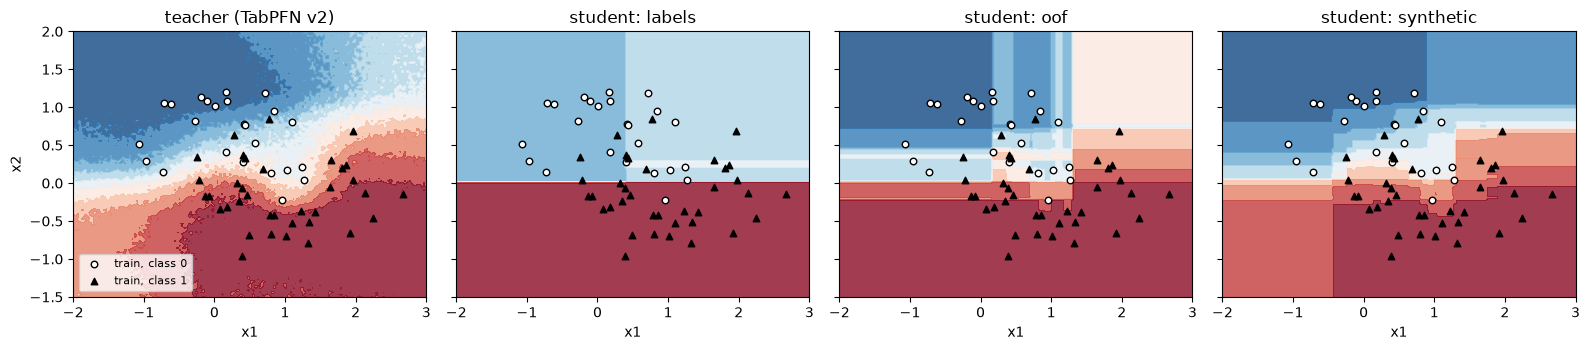

In [7]:
grid_1, grid_2 = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 120))
grid = np.column_stack([grid_1.ravel(), grid_2.ravel()])
panels = {"teacher (TabPFN v2)": teacher, **{f"student: {m}": s for m, s in students.items()}}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (title, estimator) in zip(axes, panels.items(), strict=True):
    p1 = estimator.predict_proba(grid)[:, 1].reshape(grid_1.shape)
    ax.contourf(grid_1, grid_2, p1, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.8)
    for label, marker, color in [(0, "o", "white"), (1, "^", "black")]:
        rows = y_tr == label
        ax.scatter(
            x_tr[rows, 0],
            x_tr[rows, 1],
            marker=marker,
            c=color,
            edgecolors="k",
            s=22,
            label=f"train, class {label}",
        )
    ax.set_title(title)
    ax.set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

정답만 배운 학생은 학습 행 60개로 나무를 거의 키우지 못해 평면을 칸 몇 개로만 나눕니다. teacher를 배운 두 학생은 계단 모양으로나마 teacher의 S자 경계와 경계 근처의 흐린 띠(확률 0.5 근처)를 따라갑니다. 확률을 배우면 행 하나가 "어느 쪽인가"뿐 아니라 "얼마나 확실한가"도 알려 주므로, 행이 적어도 학생이 경계의 모양을 배울 수 있습니다. synthetic 학생은 새 행 120개 덕분에 학습 행이 드문 위·아래 구석에서도 teacher를 따라갑니다.

## 5. 정리

| 방법 | 학습 행의 target | 더하는 행 | 정답 라벨 섞기 | 출처 |
|---|---|---|---|---|
| `labels` | 정답 라벨 | 없음 | 정답만 | 견주기용 |
| `oof` | teacher의 5-fold out-of-fold 확률 | 없음 | α = 0.7 (teacher 0.7, 정답 0.3) | arXiv 2605.18654 |
| `synthetic` | teacher 확률 (학습 행 전체 context) | CutMix 행 2배, teacher 확률 | α = 1 (teacher만) | arXiv 2610.01435 |

- 확률을 배우는 손실은 행을 클래스 수만큼 복제하고 가중치를 주는 것으로 바꿀 수 있습니다(1절).
- 학습 행을 그대로 물으면 teacher가 정답을 보고 답하므로, out-of-fold로 묻거나 context에 없는 행을 새로 만들어 묻습니다(2·3절).
- 예측은 학생만 하므로 GPU가 필요 없고 CPU에서도 teacher보다 훨씬 빠릅니다. 대신 teacher보다 조금 못합니다(4절).
- 평가 명령: `scripts/tabpfn_v2/eval.py --distill synthetic --student xgboost`.